In [1]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
ctc = sc.read_h5ad('/mnt/c/Users/ouyangkang/Desktop/ctc_with_anno.h5ad')

In [3]:
sample_info_mapping = {
    "C03427D3": "Sample_01",
    "C03427D4": "Sample_02",
    "A04086G2": "Sample_03",
    "A04230E4_15": "Sample_04",
    "A04088E3": "Sample_05",
    "A04086G3": "Sample_06",
    "A04227C4_13": "Sample_07",
    "A04228A4_1": "Sample_08",
    "A04227C4_14": "Sample_09",
    "A04230E4_16": "Sample_10",
    "A04229A3": "Sample_11",
    "A04232A3": "Sample_12",
    "Y00784ME_1": "Sample_13",
    "A04230E2": "Sample_14",
    "Y00723F2_1": "Sample_15",
    "Y00723F2_2": "Sample_16",
    "Y00784ME_2": "Sample_17",
    "A04224E3": "Sample_18"
}
ctc.obs['sample_info'] = ctc.obs['chip_id'].replace(sample_info_mapping)

/tmp/ipykernel_23715/3398937030.py:21: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  ctc.obs['sample_info'] = ctc.obs['chip_id'].replace(sample_info_mapping)


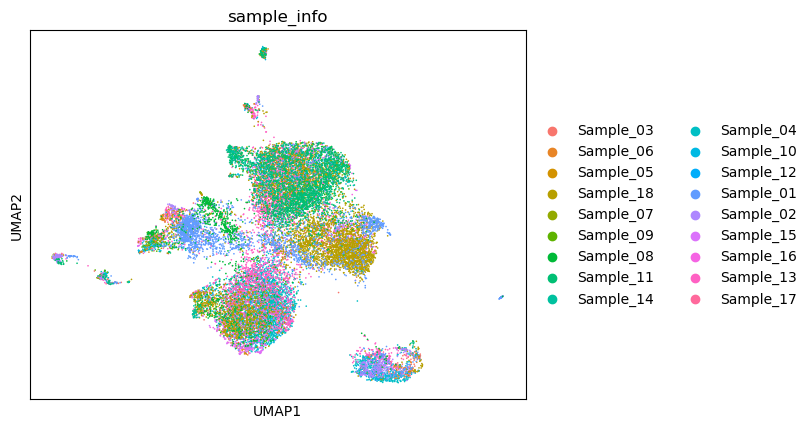

In [4]:
chip_color = {
    "Sample_03": "#F8766D",
    "Sample_06": "#E88526",
    "Sample_05": "#D39200",
    "Sample_18": "#B79F00",
    "Sample_07": "#93AA00",
    "Sample_09": "#5EB300", 
    "Sample_08": "#00BA38",
    "Sample_11": "#00BF74",
    "Sample_14": "#00C19F",
    "Sample_04": "#00BFC4",
    "Sample_10": "#00B9E3",
    "Sample_12": "#00ADFA",
    "Sample_01": "#619CFF",
    "Sample_02": "#AE87FF",
    "Sample_15": "#DB72FB",
    "Sample_16": "#F564E3", 
    "Sample_13": "#FF61C3",
    "Sample_17": "#FF699C"
}

sc.pl.umap(ctc, color='sample_info', palette=chip_color, show=False)
plt.savefig('/mnt/d/dailywork/02_ctc/plot/figs/ctc_batch_correct.pdf', dpi=300, bbox_inches='tight')

In [5]:
phage_mapping = {
    "None": "Healthy"
}

ctc.obs['phage_info'] = ctc.obs['phage_info'].replace(phage_mapping)

/tmp/ipykernel_23715/828191767.py:5: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  ctc.obs['phage_info'] = ctc.obs['phage_info'].replace(phage_mapping)


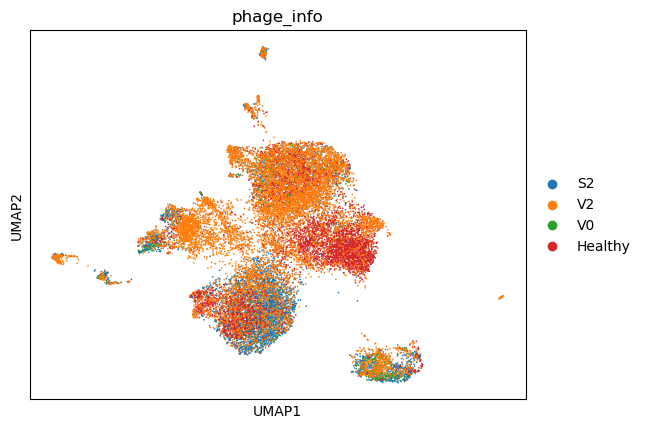

In [6]:
sc.pl.umap(ctc, color='phage_info', show=False)
plt.savefig('/mnt/d/dailywork/02_ctc/plot/figs/ctc_phage_distribution.pdf', dpi=300, bbox_inches='tight')

In [18]:
umap_info = pd.DataFrame(ctc.obsm['X_umap'], columns=['UMAP_1', 'UMAP_2'], index=ctc.obs_names)
umap_info = umap_info.join(ctc.obs['anno'])
umap_info.to_csv('/mnt/c/Users/ouyangkang/Desktop/umap.csv')

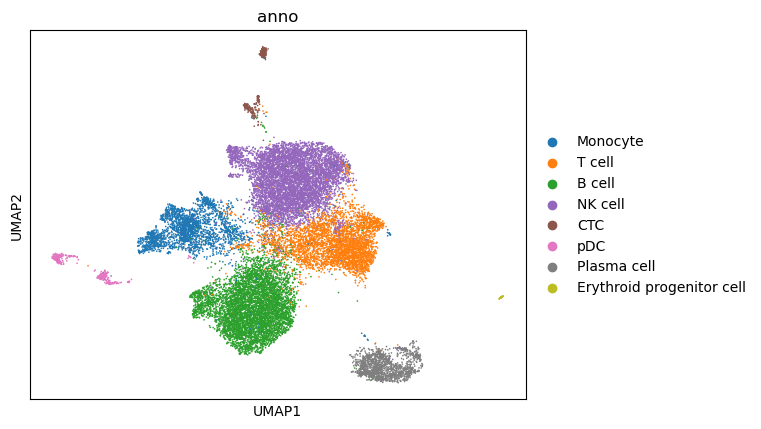

In [7]:
sc.pl.umap(ctc, color='anno')

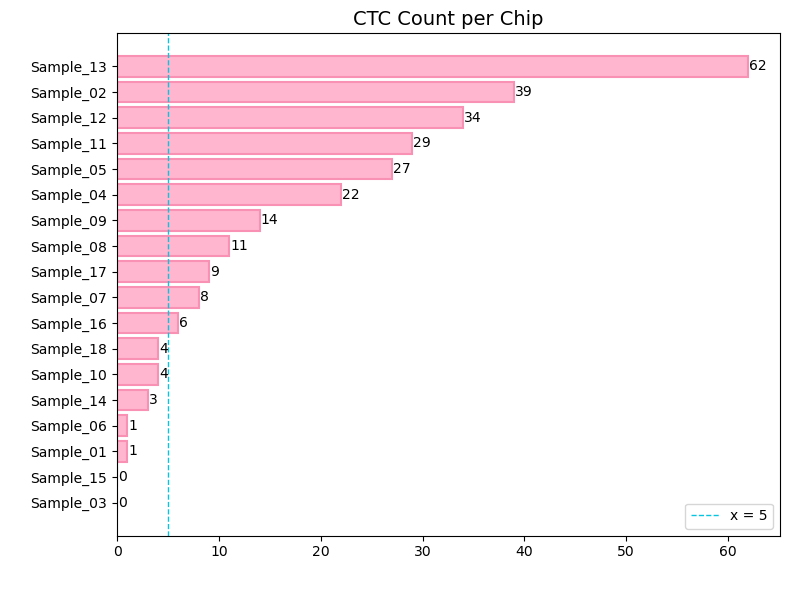

In [75]:
num_chip_df = pd.crosstab(ctc.obs['sample_info'], ctc.obs['anno_ctc'])
num_chip_df.sort_values(by='True CTC', ascending=True, inplace=True)

plt.figure(figsize=(8, 6))

fill_color = "#FFB6CE"
border_color = "#F891B3"

ax = plt.barh(num_chip_df.index, num_chip_df['True CTC'], color=fill_color, edgecolor=border_color, linewidth=1.5)

# 添加参考线
plt.axvline(x=5, color="#07c5df", linestyle='--', linewidth=1, label='x = 5')

# 添加数值标签
for i, v in enumerate(num_chip_df['True CTC']):
    plt.text(v + 0.1, i, f"{v:.0f}", va='center')

# 美化坐标轴
plt.xlabel("CTC Count", fontsize=12, color='white')
plt.ylabel("Chip ID", fontsize=12, color='white')
plt.title("CTC Count per Chip", fontsize=14, color='black')

plt.grid(False)
# 添加标签、图例
plt.xlabel("CTC Count")
plt.ylabel("Chip ID")
plt.legend()
plt.tight_layout()
plt.savefig('/mnt/d/dailywork/02_ctc/plot/figs/ctc_count_by_chip.pdf', dpi=300, bbox_inches='tight', transparent=True)

In [5]:
num_chip_df = pd.crosstab(ctc.obs['sample_info'], ctc.obs['anno_ctc'])

In [7]:
num_chip_df.index.name = None
num_chip_df.columns.name = None

In [8]:
num_chip_df.head()

,B cell,Erythroid progenitor cell,False CTC,Monocyte,NK cell,Plasma cell,T cell,True CTC,pDC
Sample_03,13,0,0,15,15,167,10,0,11
Sample_06,55,2,0,60,22,19,2,1,3
Sample_05,2,0,2,15,5,0,0,27,10
Sample_18,879,0,11,198,1202,73,2298,4,9
Sample_07,27,0,2,24,53,3,9,8,20


In [10]:
phage_anno_df = pd.crosstab(ctc.obs['phage_info'], ctc.obs['anno_ctc'])
phage_anno_df.index.name = None
phage_anno_df.columns.name = None
phage_anno_df.head()

,B cell,Erythroid progenitor cell,False CTC,Monocyte,NK cell,Plasma cell,T cell,True CTC,pDC
S2,2939,2,15,327,761,659,160,73,140
V2,2072,44,47,1836,4334,579,1373,185,250
V0,135,0,5,103,384,254,17,12,28
Healthy,879,0,11,198,1202,73,2298,4,9


In [11]:
phage_anno_df.to_csv('/mnt/d/dailywork/02_ctc/plot/plot_data/phage_celltype_df.csv')
num_chip_df.to_csv('/mnt/d/dailywork/02_ctc/plot/plot_data/chip_celltype_df.csv')

In [5]:
import cosg
n_gene=50
groupby='anno'
cosg.cosg(
   ctc,
   key_added='cosg',
   # use_raw=False, layer='log1p', ## e.g., if you want to use the log1p layer in adata
   mu=100,
   expressed_pct=0.1,
   remove_lowly_expressed=True,
   n_genes_user=30,
   groupby=groupby
)

In [6]:
sc.tl.dendrogram(ctc, groupby=groupby, use_rep='X_scVI') ## Change use_rep to the cell embeddings key you'd like to use
df_tmp=pd.DataFrame(ctc.uns['cosg']['names'][:20,]).T
df_tmp=df_tmp.reindex(ctc.uns['dendrogram_'+groupby]['categories_ordered'])
marker_genes_list={idx: list(row.values) for idx, row in df_tmp.iterrows()}
marker_genes_list = {k: v for k, v in marker_genes_list.items() if not any(isinstance(x, float) for x in v)}

In [18]:
marker_gene = [
    'CD28', 'CD3E', 'TCF7', 'IL7R', # T cells
    'CD22', 'PAX5', 'MS4A1', 'EBF1', # B cells
    "GNLY", "NKG7", "NCAM1", "KLRF1", # NK cell
    'CSF1R', 'CSF3R', 'FCN1', 'VCAN', # Monocyte
    'MZB1', 'SEC11C', 'SSR4', 'TXNDC5', # Plasma cell
    'RETN', 'RNASE2', 'MMP8', 'MCEMP1', # Erythroid progenitor cell
    'VWF', 'CDH13', 'EPCAM', 'ALDH1A1', # CTC
]

In [30]:
cell_type = ctc.obs['anno']

expression_data = pd.DataFrame(ctc[:, marker_gene].X.todense(), columns=marker_gene)
expression_data['cell_type'] = ctc.obs['anno'].values

mean_exp_by_ct = expression_data.groupby('cell_type').mean()
# order
ordered_cell_types = ['T cell', 'B cell', 'NK cell', 'Monocyte', 'Plasma cell', 'Erythroid progenitor cell', 'CTC']

mean_exp_by_ct = mean_exp_by_ct.loc[ordered_cell_types]

# z score
mean = np.mean(mean_exp_by_ct, axis=0)
std_dev = np.std(mean_exp_by_ct, axis=0)
scale_data = (mean_exp_by_ct - mean) / std_dev

/tmp/ipykernel_521/1991834404.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_exp_by_ct = expression_data.groupby('cell_type').mean()


In [ ]:
scale_data = scale_data.T.rename(columns={"Erythroid progenitor cell": "EPC"})

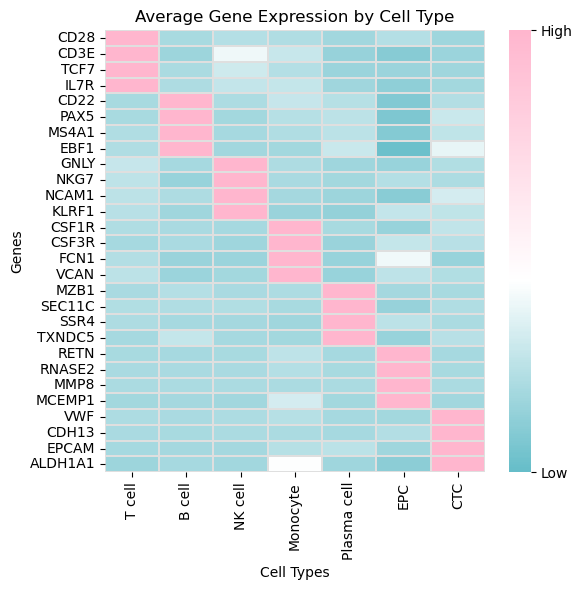

In [ ]:
from matplotlib import colors

custom_colors = ["#65c2ce", "white", "#FFB6CE"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=256)

plt.figure(figsize=(6, 6))

ax = sns.heatmap(scale_data, cmap=cmap_custom, annot=False, vmax=2, vmin=-1, center=0.3,
                linewidths=0.003, cbar=True, linecolor="#DFDFDF")
'''
n_genes = scale_data.T.shape[0]
n_cols = scale_data.T.shape[1]
ct_list = [i for i in scale_data.index for _ in range(4)]

for i, anno in enumerate(ct_list):
    ax.text(n_cols + 0.1,         # x坐标：热图最右侧+偏移量
            i + 0.1,              # y坐标：行中心位置
            anno,             # 注释文本
            ha='left',            # 水平左对齐
            va='center',          # 垂直居中
            fontsize=10,          # 字体大小
            color='black') 
'''

cbar = ax.collections[0].colorbar
cbar.set_ticks([-1, 2])
cbar.set_ticklabels(['Low', 'High'])

plt.title('Average Gene Expression by Cell Type')
plt.xlabel('Cell Types')
plt.ylabel('Genes')
plt.tight_layout()
plt.savefig('/mnt/d/dailywork/02_ctc/plot/figs/ctc_anno_heatmap.pdf', dpi=300, bbox_inches='tight')

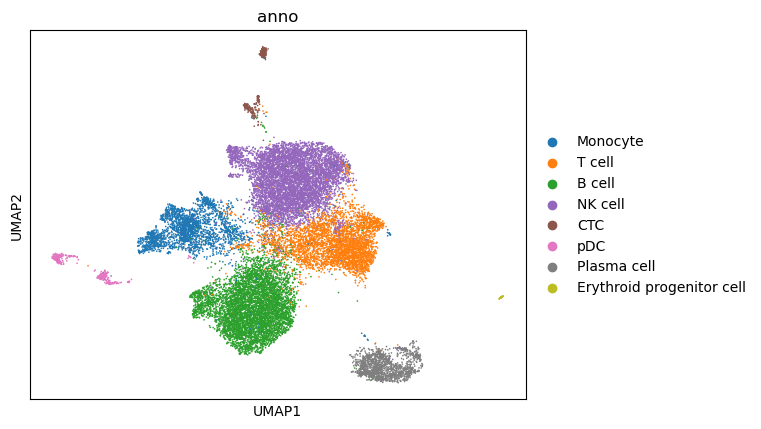

In [6]:
sc.pl.umap(ctc, color='anno')

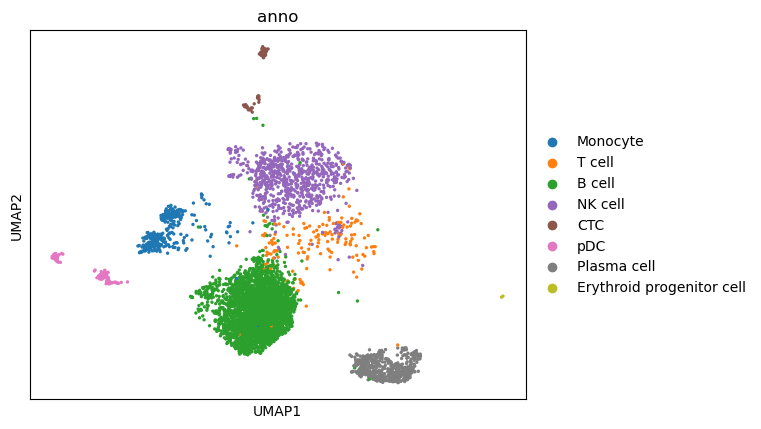

In [14]:
tmp_index = ctc.obs[ctc.obs['phage_info'] == 'S2'].index
sc.pl.umap(ctc[tmp_index, :], color=['anno'])

In [23]:
tmp_index = ctc.obs[~ctc.obs['anno_ctc'].isin(['False CTC'])].index
ctc = ctc[tmp_index, :]

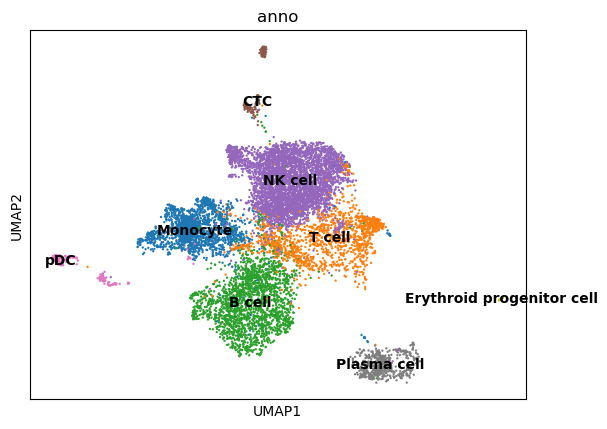

In [25]:
tmp_index = ctc.obs[ctc.obs['phage_info'] == 'V2'].index
sc.pl.umap(ctc[tmp_index, :], color=['anno'], legend_loc='on data')

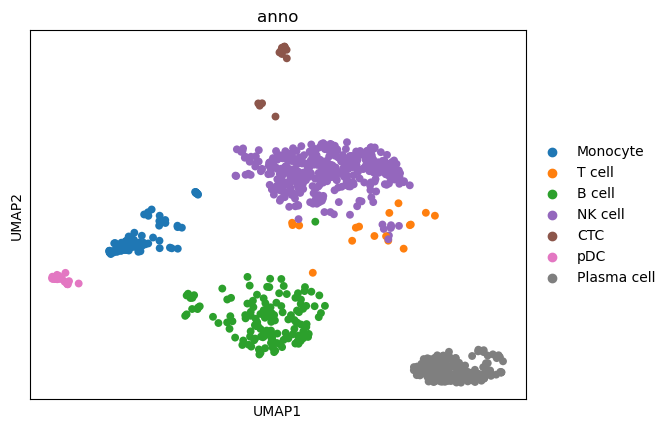

In [17]:
tmp_index = ctc.obs[ctc.obs['phage_info'] == 'V0'].index
sc.pl.umap(ctc[tmp_index, :], color=['anno'])

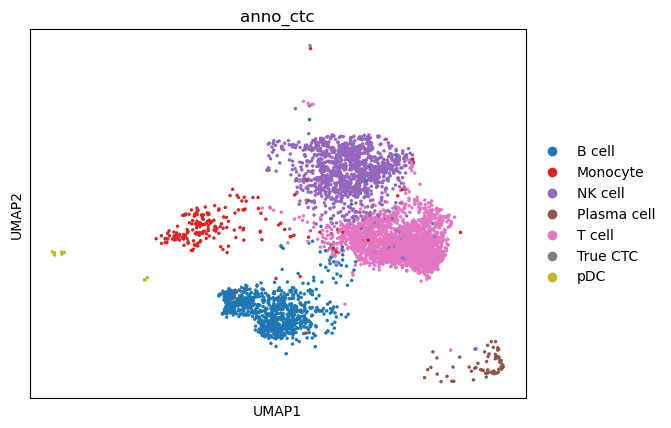

In [28]:
tmp_index = ctc.obs[ctc.obs['phage_info'] == 'Healthy'].index
sc.pl.umap(ctc[tmp_index, :], color=['anno_ctc'], size=25)